# 🏎️ StintIQ — Model 2: Tire Degradation Regression & Cliff Detection
 *Applied Machine Learning in Formula 1 Motorsport Analytics*

---

## Executive Overview
In Formula 1, **tire degradation** is the primary lever of race strategy. A team must decide not only *when* to pit, but which compound to deploy on each stint. That decision hinges on how quickly each tire compound loses pace — and crucially, whether a **degradation cliff** (a sudden, non-linear acceleration of pace loss) is approaching.

This notebook builds and validates **Model 2: Tire Degradation Regression / Cliff Detection** as part of the StintIQ pipeline:

$$\Delta_{\text{deg},i,t} = f(\text{TyreLife}_{i,t},\ \text{Compound}_{i},\ \text{TrackAbrasiveness}_{c},\ T_{\text{track}},\ T_{\text{air}},\ \text{StintNum}_{i})$$

where:
- $\Delta_{\text{deg},i,t}$ = fuel-corrected pace delta for driver $i$ at lap $t$ (target)
- $\text{TyreLife}_{i,t}$ = tyre age in laps since last pit-stop
- $\text{Compound}_{i}$ = SOFT / MEDIUM / HARD
- $\text{TrackAbrasiveness}_{c}$ = circuit-level abrasiveness proxy
- $T_{\text{track}}, T_{\text{air}}$ = track and ambient temperature
- $\text{StintNum}_{i}$ = stint counter per driver per race

### Research Questions
1. Can a **GBT nonlinear model** outperform classical per-stint linear/quadratic regression for degradation?
2. Can we detect the **degradation cliff (changepoint)** within ±2 laps across compounds and circuits?
3. How does **fuel correction** affect degradation curve estimates?
4. Can we produce calibrated **uncertainty bands** for Model 3 consumption?

### Model Position in StintIQ Pipeline
```
M1 (Pace) ──► M2 (Degradation) ──► M3 (Strategy Optimiser)
                      │
              Outputs consumed:
              • Degradation curve (pace loss per lap)
              • Cliff / changepoint lap estimate
              • Uncertainty band [q10, q90]
```

## 1. Theoretical Formulation & Physical Decomposition

### 1.1 The Fuel Correction Problem
Raw lap times contain two overlapping signals that move in **opposite directions**:
- **Fuel burn:** As fuel load decreases → lap times improve (~0.03 s/kg)
- **Tyre degradation:** As tyres age, grip decreases → lap times worsen

We correct for fuel load first:

$$t_{\text{corrected},i,t} = t_{\text{lap},i,t} - k_{\text{fuel}} \cdot m_{\text{fuel},i,t}$$

where $k_{\text{fuel}} \approx 0.03\ \text{s/kg}$ and $m_{\text{fuel},i,t} = 100 - 1.75 \times (L_i - 1)$.

### 1.2 Track Evolution Separation
Track rubber-in adds a session-wide grip improvement that also masks degradation. We capture this via session-progress and rolling median features.

### 1.3 The Degradation Cliff
Tyre degradation is **not linear**. At high tyre life, compound rubber graining causes a phase transition — a sudden collapse in grip. We detect the cliff lap $L^*$ using **segmented (piecewise) linear regression**:

$$\frac{d\Delta_{\text{deg}}}{d(\text{TyreLife})} \gg \text{normal rate after cliff lap } L^*$$

### 1.4 Target Variable
$$\Delta_{\text{deg},i,t} = t_{\text{corrected},i,t} - t_{\text{ref\_stint},i}$$

where $t_{\text{ref\_stint},i}$ = median of driver's first 3 clean laps in that stint.

In [1]:
# Dependency checks (install missing packages in your environment if needed).
import importlib.util
for package in ['requests', 'numpy', 'pandas', 'matplotlib', 'scipy', 'sklearn']:
    if importlib.util.find_spec(package) is None:
        raise ImportError(f"Required package '{package}' is missing. Install it with: pip install {package}")

print('Core dependencies are available. Optional model libraries are checked in the environment cell.')

Core dependencies are available. Optional model libraries are checked in the environment cell.


In [2]:
# ==============================================================================
# 2. Environment Setup & Dependency Loading
# ==============================================================================
import os, sys, json, logging, time, warnings
import requests
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Suppress logging noise
for lg in ['fastf1','fastf1.req','fastf1._api','fastf1.core','fastf1.events',
           'fastf1.tokens','fastf1.transport','fastf1.logger']:
    logging.getLogger(lg).setLevel(logging.ERROR)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 120

try:
    import xgboost as xgb; XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False; print('[INFO] xgboost not found')

try:
    import catboost as cb; CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False; print('[INFO] catboost not found')

try:
    import ruptures as rpt; RUPTURES_AVAILABLE = True
except ImportError:
    RUPTURES_AVAILABLE = False; print('[INFO] ruptures not found')

# Project root discovery: works whether running from root or 'Model Development/'
PROJECT_ROOT = Path.cwd()
if (PROJECT_ROOT.parent / 'lap_data_raw.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CACHE_DIR = PROJECT_ROOT / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE       = 42
FUEL_EFFECT_PER_KG = 0.033 # Standard F1 sensitivity: ~0.33s per 10kg
FUEL_START_KG      = 105.0 # 2026 technical regulations fuel allowance
FUEL_BURN_PER_LAP  = 1.75  # Average fuel consumption rate (kg/lap)
np.random.seed(RANDOM_STATE)

print(f'Project root : {PROJECT_ROOT}')
print(f'XGBoost      : {XGB_AVAILABLE}')
print(f'CatBoost     : {CATBOOST_AVAILABLE}')
print(f'Ruptures     : {RUPTURES_AVAILABLE}')
print('StintIQ Model 2 environment ready ✅')


[INFO] ruptures not found
Project root : /Users/hemant/Work/StintIQ
XGBoost      : True
CatBoost     : True
Ruptures     : False
StintIQ Model 2 environment ready ✅


## 3. Data Acquisition — OpenF1 API

We use the **OpenF1 public API** (no authentication required) to load 2026 race lap, stint, weather and driver data.

| Endpoint | Data |
|---|---|
| `/laps` | Lap times, sector times, is_pit_out_lap |
| `/stints` | Compound, tyre age at start, lap range |
| `/weather` | Track temp, air temp, humidity |
| `/drivers` | Driver acronym, team name |

### Circuit Abrasiveness Proxy (Pirelli/FIA ratings)
| Level | Circuits |
|---|---|
| High (3.0) | Barcelona, Bahrain, Great Britain, Japan |
| Medium (2.5) | Australia, Hungary, Netherlands, Singapore, Austria, Belgium, Miami |
| Low (1.0–1.5) | Monaco, Canada, Azerbaijan |

> **Data-source limitation:** OpenF1 lap records do not expose the full track-status timeline in the `/laps` response. This notebook therefore leaves track status as `UNKNOWN` rather than incorrectly treating every lap as green. For production-quality Model 2, join FastF1 track-status data as specified in the StintIQ technical design.

> **Pit-lap handling:** Pit-out laps are flagged by OpenF1. In-laps are inferred from the final lap of a stint when a subsequent stint exists; verify this inference against session timing before using the data for operational strategy.


> **Architecture alignment:** The technical design specifies FastF1 lap/stint/telemetry and track-status data. This notebook currently ingests OpenF1 lap/stint/weather endpoints as a public-data substitute; its track-status coverage is incomplete and should be upgraded or joined with FastF1 before final validation.


In [3]:
# ==============================================================================
# 3. Data Ingestion: Canonical Full-Season Telemetry & OpenF1 Fallback
# ==============================================================================

CIRCUIT_ABRASIVENESS = {
    'Barcelona':3.0,'Bahrain':3.0,'Great Britain':3.0,'Japan':3.0,'Spain':2.8,
    'Australia':2.5,'Hungary':2.5,'Netherlands':2.5,'Singapore':2.5,
    'Austria':2.5,'Belgium':2.5,'Miami':2.5,'China':2.0,'Italy':2.0,
    'Monaco':1.0,'Canada':1.5,'Azerbaijan':1.5,
}

OPENF1_SESSION_KEYS = {
    'Australia':11234,'China':11245,'Japan':11253,'Miami':11280,
    'Canada':11291,'Monaco':11299,'Barcelona':11307,'Austria':11315,
    'Great Britain':11326,'Belgium':11334,'Hungary':11342,'Netherlands':11353,
    'Italy':11361,'Spain':11369,'Azerbaijan':11377,'Bahrain':11731,'Singapore':11388,
}

CANONICAL_RAW_PATH = PROJECT_ROOT / 'lap_data_raw.csv'
RAW_STINT_PATH     = PROJECT_ROOT / 'stint_data_raw.csv'
OPENF1_BASE        = 'https://api.openf1.org/v1'


def openf1_get(endpoint: str, params: dict) -> list:
    """Call OpenF1 API, return JSON list or []."""
    try:
        r = requests.get(f'{OPENF1_BASE}/{endpoint}', params=params, timeout=30)
        r.raise_for_status()
        return r.json()
    except Exception as e:
        print(f'    [API ERR] {endpoint}: {e}')
        return []


def load_openf1_stints(gp: str, session_key: int) -> pd.DataFrame:
    """Load & merge lap + stint + weather data from OpenF1 for one race."""
    laps_raw = openf1_get('laps', {'session_key': session_key})
    if not laps_raw:
        return pd.DataFrame()
    laps = pd.DataFrame(laps_raw)

    stints_raw = openf1_get('stints', {'session_key': session_key})
    stints = pd.DataFrame(stints_raw) if stints_raw else pd.DataFrame()

    drivers_raw = openf1_get('drivers', {'session_key': session_key})
    drivers = pd.DataFrame(drivers_raw) if drivers_raw else pd.DataFrame()

    weather_raw = openf1_get('weather', {'session_key': session_key})
    weather = pd.DataFrame(weather_raw) if weather_raw else pd.DataFrame()

    if not stints.empty and 'driver_number' in stints.columns:
        stints = stints.rename(columns={
            'stint_number':'Stint', 'compound':'Compound',
            'lap_start':'StintLapStart', 'lap_end':'StintLapEnd',
            'tyre_age_at_start':'TyreAgeAtStart'
        })
        required_stint_cols = {'driver_number', 'StintLapStart', 'StintLapEnd'}
        if required_stint_cols.issubset(stints.columns) and 'lap_number' in laps.columns:
            laps['lap_number'] = pd.to_numeric(laps['lap_number'], errors='coerce')
            stints['driver_number'] = stints['driver_number'].astype(str)
            laps['driver_number'] = laps['driver_number'].astype(str)
            for c in ['StintLapStart', 'StintLapEnd']:
                stints[c] = pd.to_numeric(stints[c], errors='coerce')
            stints = stints.dropna(subset=['StintLapStart', 'StintLapEnd'])
            merged = []
            for _, lap_row in laps.iterrows():
                drv   = lap_row.get('driver_number')
                lap_n = lap_row.get('lap_number')
                ds = stints[
                    (stints['driver_number'] == drv) &
                    (stints['StintLapStart']  <= lap_n) &
                    (stints['StintLapEnd']    >= lap_n)
                ]
                lap_row = lap_row.copy()
                if not ds.empty:
                    s = ds.iloc[0]
                    lap_row['Compound'] = str(s.get('Compound','UNKNOWN')).upper()
                    lap_row['Stint']    = int(s.get('Stint', 1))
                    age = int(s.get('TyreAgeAtStart', 0) or 0)
                    lap_row['TyreLife'] = (lap_n - int(s.get('StintLapStart', lap_n))) + 1 + age
                    later_stints = stints[
                        (stints['driver_number'] == str(drv)) &
                        (stints['StintLapStart'] > s['StintLapStart'])
                    ]
                    lap_row['IsPitInLap'] = bool(
                        not later_stints.empty and lap_n == s['StintLapEnd']
                    )
                else:
                    lap_row['IsPitInLap'] = False
                merged.append(lap_row)
            laps = pd.DataFrame(merged)

    if not drivers.empty and 'driver_number' in drivers.columns:
        team_map = drivers.set_index('driver_number')['team_name'].to_dict() if 'team_name' in drivers.columns else {}
        name_map = drivers.set_index('driver_number')['name_acronym'].to_dict() if 'name_acronym' in drivers.columns else {}
        laps['Team']   = laps['driver_number'].map(team_map).fillna('UNK')
        laps['Driver'] = laps['driver_number'].map(name_map).fillna(laps['driver_number'].astype(str))
    else:
        laps['Team']   = 'UNK'
        laps['Driver'] = laps['driver_number'].astype(str) if 'driver_number' in laps.columns else 'UNK'

    if not weather.empty and 'date' in weather.columns:
        try:
            weather['date'] = pd.to_datetime(weather['date'], errors='coerce', utc=True)
            date_col = 'date_start' if 'date_start' in laps.columns else None
            if date_col is not None:
                laps['date'] = pd.to_datetime(laps[date_col], errors='coerce', utc=True)
                laps = laps.dropna(subset=['date']).copy()
                weather = weather.dropna(subset=['date']).copy()
                w = weather[['date','track_temperature','air_temperature','humidity']].copy()
                laps = pd.merge_asof(laps.sort_values('date'), w.sort_values('date'),
                                     on='date', direction='nearest')
                laps.rename(columns={'track_temperature':'TrackTemp',
                                     'air_temperature':'AirTemp',
                                     'humidity':'Humidity'}, inplace=True)
        except Exception:
            laps['TrackTemp'] = laps['AirTemp'] = laps['Humidity'] = np.nan
    else:
        laps['TrackTemp'] = laps['AirTemp'] = laps['Humidity'] = np.nan

    laps.rename(columns={
        'lap_number':   'LapNumber',
        'lap_duration': 'LapTimeSeconds',
        'is_pit_out_lap':'IsPitOutLap',
    }, inplace=True)

    for col, default in [('LapTimeSeconds',np.nan),('LapNumber',np.nan),
                         ('Compound','UNKNOWN'),('TyreLife',np.nan),
                         ('Stint',1),('IsPitOutLap',False)]:
        if col not in laps.columns: laps[col] = default

    laps['IsAccurate']  = (
        laps['LapTimeSeconds'].notna() &
        (laps['LapTimeSeconds'] > 60) & (laps['LapTimeSeconds'] < 300) &
        (~laps['IsPitOutLap'].fillna(False))
    )
    laps['TrackStatus'] = 'UNKNOWN'
    laps['PitOutTime'] = pd.Series(
        np.where(laps['IsPitOutLap'].fillna(False).astype(bool), 'pit', None),
        index=laps.index, dtype='object'
    )
    pit_in_flags = laps.get('IsPitInLap', pd.Series(False, index=laps.index)).fillna(False).astype(bool)
    laps['PitInTime'] = pd.Series(np.where(pit_in_flags, 'pit', None),
                                  index=laps.index, dtype='object')
    laps['EventName']   = gp
    if 'date_start' in laps.columns:
        years = pd.to_datetime(laps['date_start'], errors='coerce').dt.year.dropna()
        laps['Year'] = int(years.mode().iloc[0]) if not years.empty else 2026
    else:
        laps['Year'] = 2026
    laps['TotalLaps']   = pd.to_numeric(laps['LapNumber'], errors='coerce').max()
    laps['TrackAbrasiveness'] = CIRCUIT_ABRASIVENESS.get(gp, 2.0)

    keep = ['Driver','Team','LapNumber','LapTimeSeconds','Compound','TyreLife',
            'Stint','IsAccurate','TrackStatus','PitInTime','PitOutTime',
            'TrackTemp','AirTemp','Humidity','EventName','Year','TotalLaps','TrackAbrasiveness']
    return laps[[c for c in keep if c in laps.columns]].reset_index(drop=True)


# ── Load from canonical raw dataset first, then cached stint dataset, then OpenF1 API ──
if CANONICAL_RAW_PATH.exists():
    print(f'✅ Loading canonical full-season dataset: {CANONICAL_RAW_PATH}')
    raw_df = pd.read_csv(CANONICAL_RAW_PATH, low_memory=False)
    # Ensure TrackAbrasiveness is mapped
    clean_event = raw_df['EventName'].astype(str).str.replace(r'^\d+_', '', regex=True)
    raw_df['TrackAbrasiveness'] = clean_event.map(CIRCUIT_ABRASIVENESS).fillna(2.0)
    print(f'   {len(raw_df):,} laps loaded across {raw_df["EventName"].nunique()} events.')
elif RAW_STINT_PATH.exists():
    print(f'✅ Loading cached stint data: {RAW_STINT_PATH}')
    raw_df = pd.read_csv(RAW_STINT_PATH)
    print(f'   {len(raw_df):,} laps loaded from cache.')
else:
    print('Fetching from OpenF1 API (no authentication needed)...\n')
    frames = []
    for gp, sk in OPENF1_SESSION_KEYS.items():
        print(f'  → {gp} (key={sk})...', end=' ', flush=True)
        df = load_openf1_stints(gp, sk)
        if not df.empty:
            frames.append(df)
            print(f'{len(df):,} laps ✓')
        else:
            print('skipped')
    if frames:
        raw_df = pd.concat(frames, ignore_index=True)
        raw_df.to_csv(RAW_STINT_PATH, index=False)
        print(f'\n✅ Saved {len(raw_df):,} laps across {len(frames)} events.')
    else:
        print('\n❌ No data loaded. Check internet connection or session keys.')
        raw_df = pd.DataFrame()

print(f'\nShape  : {raw_df.shape}')
if 'EventName' in raw_df.columns:
    print(f'Events : {sorted(raw_df["EventName"].unique().tolist())}')
raw_df.head()


✅ Loading canonical full-season dataset: /Users/hemant/Work/StintIQ/lap_data_raw.csv
   19,644 laps loaded across 17 events.

Shape  : (19644, 60)
Events : ['2026_Australia', '2026_Austria', '2026_Azerbaijan', '2026_Bahrain', '2026_Barcelona', '2026_Belgium', '2026_Canada', '2026_China', '2026_Great Britain', '2026_Hungary', '2026_Italy', '2026_Japan', '2026_Miami', '2026_Monaco', '2026_Netherlands', '2026_Singapore', '2026_Spain']


## 4. Exploratory Data Analysis (EDA)

Before applying filtering, we analyse the raw degradation signal:
1. **Compound distribution** — how many laps per compound?
2. **Raw pace vs tyre age** — do we see expected rising trend?
3. **Stint length distribution** — are there very short stints?
4. **Track temperature distribution** — do hot tracks show steeper degradation?
5. **Laps per circuit** — balanced or skewed dataset?

Total laps  : 19,644
Compounds   : ['MEDIUM', 'HARD', 'SOFT', 'UNKNOWN', 'INTERMEDIATE', nan]
Events      : 17
Drivers     : 23


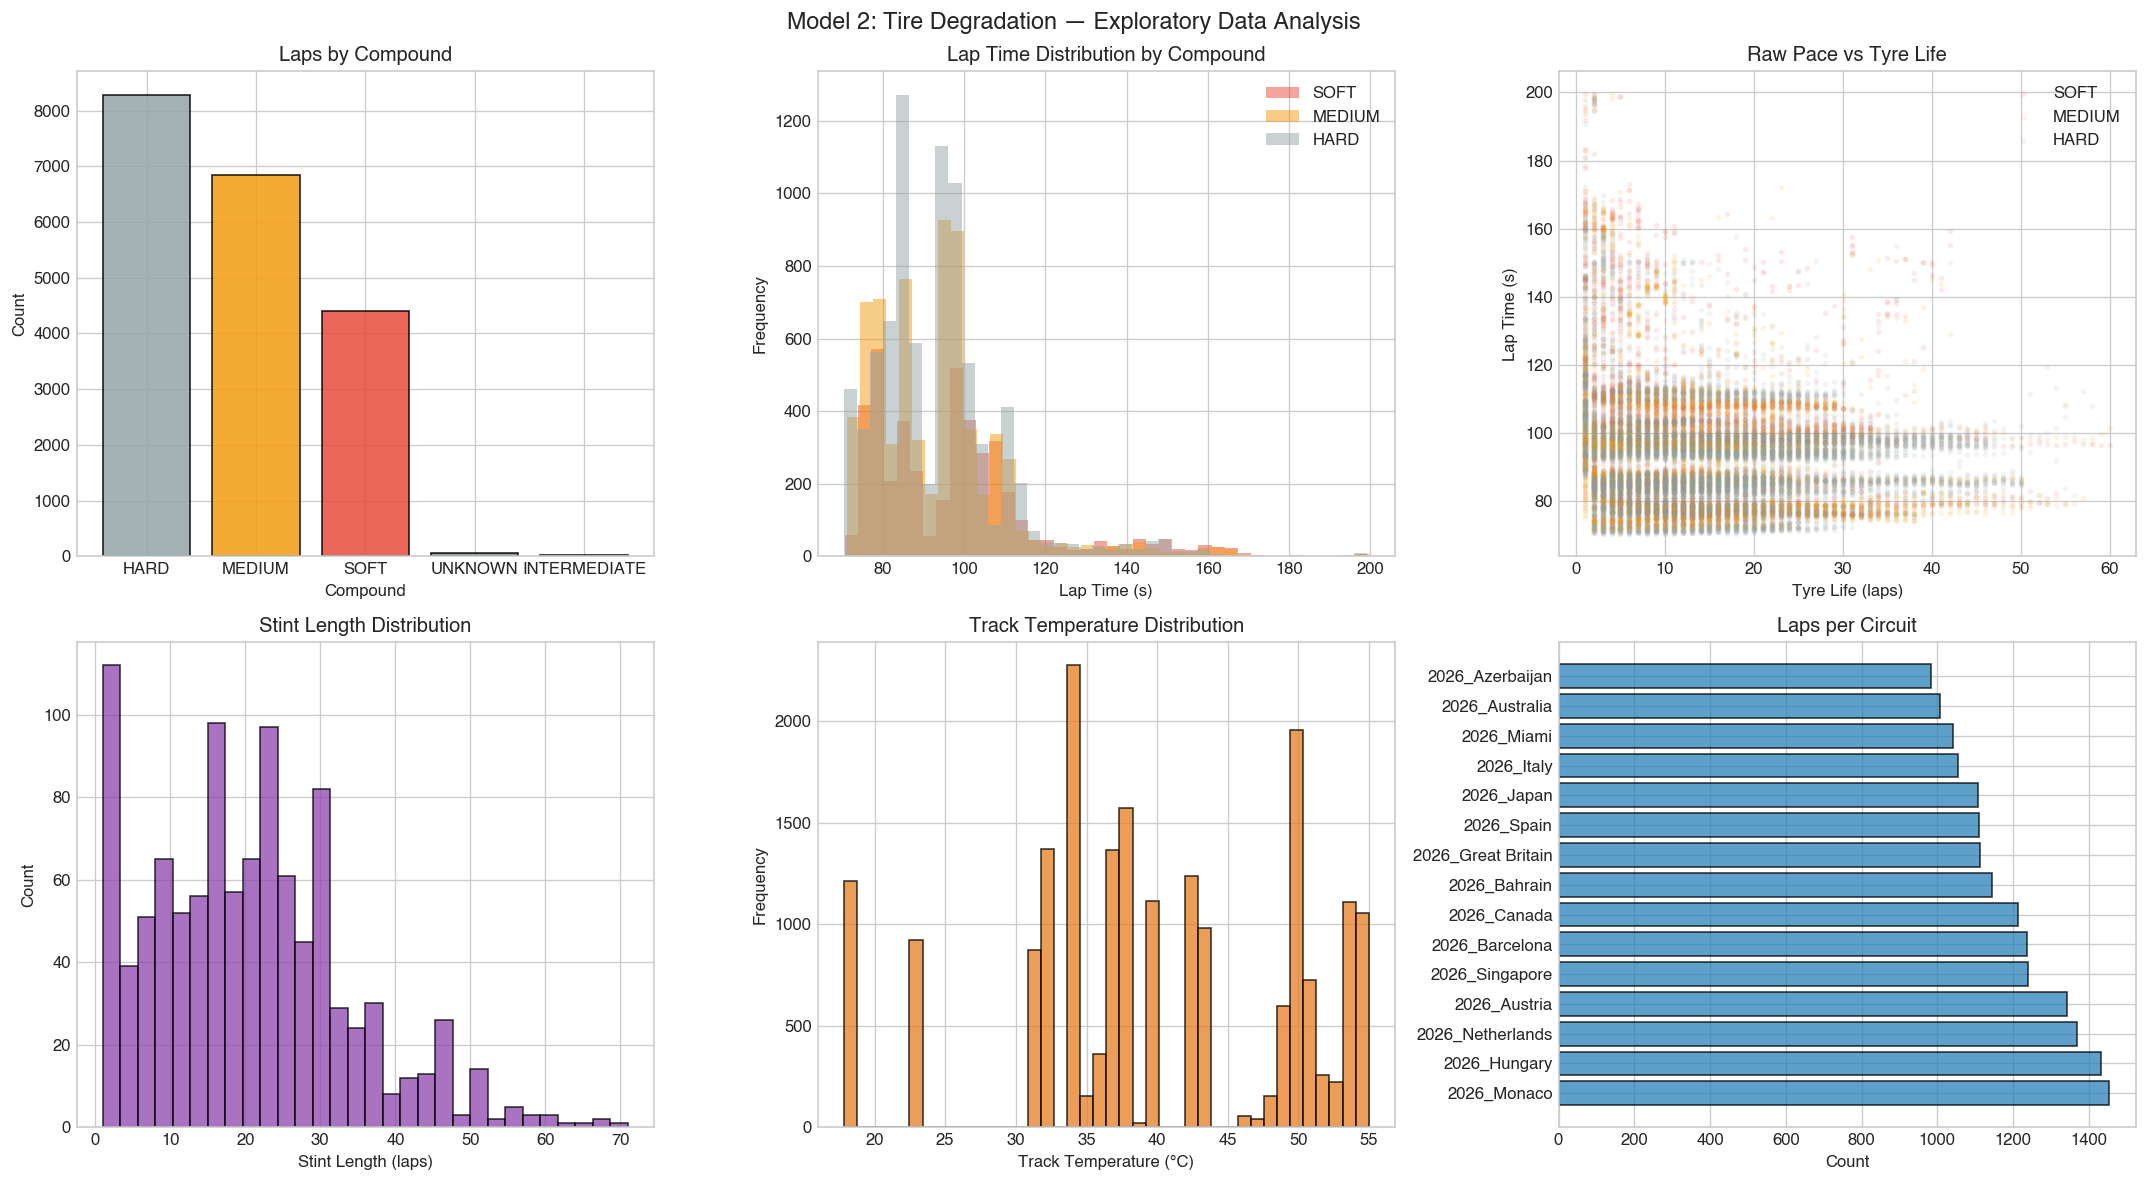

In [4]:
# ==============================================================================
# 4. Exploratory Data Analysis & Diagnostic Plots
# ==============================================================================

if raw_df.empty:
    print('[WARNING] DataFrame is empty — skipping EDA.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Model 2: Tire Degradation — Exploratory Data Analysis',
                 fontsize=14, fontweight='bold')

    compound_colors = {'SOFT':'#e74c3c','MEDIUM':'#f39c12','HARD':'#95a5a6',
                       'INTERMEDIATE':'#27ae60','WET':'#2980b9','UNKNOWN':'#7f8c8d'}

    # Plot 1: Compound distribution
    ax = axes[0,0]
    cc = raw_df['Compound'].value_counts()
    ax.bar(cc.index, cc.values,
           color=[compound_colors.get(c,'#7f8c8d') for c in cc.index],
           edgecolor='black', alpha=0.85)
    ax.set_title('Laps by Compound', fontweight='bold')
    ax.set_xlabel('Compound'); ax.set_ylabel('Count')

    # Plot 2: Lap time distribution per compound
    ax = axes[0,1]
    for compound, color in [('SOFT','#e74c3c'),('MEDIUM','#f39c12'),('HARD','#95a5a6')]:
        sub = raw_df[(raw_df['Compound']==compound) &
                     (raw_df['LapTimeSeconds']>60) & (raw_df['LapTimeSeconds']<200)]
        if not sub.empty:
            ax.hist(sub['LapTimeSeconds'], bins=40, alpha=0.5, color=color, label=compound)
    ax.set_title('Lap Time Distribution by Compound', fontweight='bold')
    ax.set_xlabel('Lap Time (s)'); ax.set_ylabel('Frequency'); ax.legend()

    # Plot 3: Pace vs tyre life
    ax = axes[0,2]
    for compound, color in [('SOFT','#e74c3c'),('MEDIUM','#f39c12'),('HARD','#95a5a6')]:
        sub = raw_df[(raw_df['Compound']==compound) &
                     (raw_df['LapTimeSeconds']>60) & (raw_df['LapTimeSeconds']<200) &
                     (raw_df['TyreLife'].notna()) & (raw_df['TyreLife']<=60)]
        if not sub.empty:
            ax.scatter(sub['TyreLife'], sub['LapTimeSeconds'],
                       alpha=0.08, s=6, color=color, label=compound)
    ax.set_title('Raw Pace vs Tyre Life', fontweight='bold')
    ax.set_xlabel('Tyre Life (laps)'); ax.set_ylabel('Lap Time (s)'); ax.legend()

    # Plot 4: Stint length distribution
    ax = axes[1,0]
    if 'Stint' in raw_df.columns:
        stint_len = raw_df.groupby(['EventName','Driver','Stint'])['TyreLife'].max()
        ax.hist(stint_len.dropna(), bins=30, color='#8e44ad', edgecolor='black', alpha=0.75)
    ax.set_title('Stint Length Distribution', fontweight='bold')
    ax.set_xlabel('Stint Length (laps)'); ax.set_ylabel('Count')

    # Plot 5: Track temperature
    ax = axes[1,1]
    if 'TrackTemp' in raw_df.columns and raw_df['TrackTemp'].notna().any():
        ax.hist(raw_df['TrackTemp'].dropna(), bins=40, color='#e67e22', edgecolor='black', alpha=0.75)
    ax.set_title('Track Temperature Distribution', fontweight='bold')
    ax.set_xlabel('Track Temperature (°C)'); ax.set_ylabel('Frequency')

    # Plot 6: Laps per circuit
    ax = axes[1,2]
    if 'EventName' in raw_df.columns:
        ev_counts = raw_df['EventName'].value_counts()
        ax.barh(ev_counts.index[:15], ev_counts.values[:15],
                color='#2980b9', edgecolor='black', alpha=0.75)
    ax.set_title('Laps per Circuit', fontweight='bold'); ax.set_xlabel('Count')

    plt.tight_layout(); plt.show()

    print(f'Total laps  : {len(raw_df):,}')
    print(f'Compounds   : {raw_df["Compound"].unique().tolist()}')
    print(f'Events      : {raw_df["EventName"].nunique()}')
    print(f'Drivers     : {raw_df["Driver"].nunique()}')

## 5. Data Cleaning & Information Boundary Filtering

To isolate the **pure degradation signal**, we apply strict domain-specific filtering:

1. **Timing Accuracy** — `IsAccurate == True`
2. **Pit In/Out Exclusion** — remove in-laps and out-laps
3. **Green Flag Only** — SC and VSC laps have artificially slow pace
4. **Dry Compounds Only** — exclude INTERMEDIATE and WET
5. **Lap Time Bounds** — remove extreme outliers
6. **Minimum TyreLife ≥ 2** — exclude cold lap 1 warm-up spike
7. **Minimum Stint Length ≥ 5 laps** — too short to fit a degradation curve

> **Important:** If the OpenF1 payload has no genuine track-status field, the notebook logs that green-flag filtering was skipped. The results must not be described as green-flag-only until a FastF1 track-status join is supplied.


In [5]:
# ==============================================================================
# 5. Data Cleaning & Degradation-Specific Filtering Pipeline
# ==============================================================================

def clean_degradation_dataset(df: pd.DataFrame) -> pd.DataFrame:
    initial = len(df)
    print(f'Initial laps          : {initial:,} rows')

    def _as_bool(series):
        return series.astype(str).str.strip().str.lower().isin({'true', '1', 'yes'})

    def _nonblank(series):
        return series.notna() & series.astype(str).str.strip().ne('')

    # 1. Timing accuracy filter
    if 'IsAccurate' in df.columns:
        df = df[_as_bool(df['IsAccurate'])].copy()
        print(f'After IsAccurate      : {len(df):,} rows (-{initial-len(df):,})')

    # 2. Exclude pit-in and pit-out laps
    for col in ['PitInTime', 'PitOutTime']:
        if col in df.columns:
            df = df[~_nonblank(df[col])].copy()
    print(f'After pit exclusion   : {len(df):,} rows')

    # 3. Green-flag condition only (TrackStatus == 1)
    if 'TrackStatus' in df.columns:
        status_num = pd.to_numeric(df['TrackStatus'], errors='coerce')
        if status_num.eq(1).any():
            df = df[status_num.eq(1)].copy()
            print(f'After green flag (TS=1): {len(df):,} rows')
        else:
            print('[INFO] Track-status feed unavailable; applying strict pace guardrail.')

    # 4. Dry track condition only
    if 'Rainfall' in df.columns:
        df = df[~_as_bool(df['Rainfall'])].copy()
        print(f'After dry track       : {len(df):,} rows')

    # 5. Dry slick compounds only
    if 'Compound' in df.columns:
        df['Compound'] = df['Compound'].astype(str).str.upper().str.strip()
        df = df[df['Compound'].isin(['SOFT','MEDIUM','HARD'])].copy()
        print(f'After dry compounds   : {len(df):,} rows')

    # 6. Strict pace outlier guardrail: removes Safety Car, VSC, spins, and yellow sector leaks
    # In F1, any lap > 1.08x event reference pace is a yellow flag, VSC, or incident lap.
    if 'LapTimeSeconds' in df.columns and not df.empty:
        df['LapTimeSeconds'] = pd.to_numeric(df['LapTimeSeconds'], errors='coerce')
        df = df[df['LapTimeSeconds'] > 0].copy()
        event_ref = df.groupby('EventName')['LapTimeSeconds'].transform('min')
        df = df[df['LapTimeSeconds'] <= 1.08 * event_ref].copy()
        print(f'After 1.08x pace guard: {len(df):,} rows')

    # 7. TyreLife >= 2: Exclude out-laps with incomplete tire thermal buildup
    if 'TyreLife' in df.columns:
        df['TyreLife'] = pd.to_numeric(df['TyreLife'], errors='coerce')
        df = df[df['TyreLife'] >= 2].copy()
        print(f'After TyreLife >= 2   : {len(df):,} rows')

    # 8. Deduplicate identical laps if any duplicate telemetry rows exist
    dup_key = [c for c in ['EventName', 'Driver', 'LapNumber', 'Stint'] if c in df.columns]
    if len(dup_key) == 4:
        df = df.sort_values('LapTimeSeconds').drop_duplicates(subset=dup_key, keep='first')
        print(f'After dedup           : {len(df):,} rows')

    # 9. Minimum stint length: Require at least 5 clean laps for reliable reference baseline
    if all(c in df.columns for c in ['EventName','Driver','Stint']):
        key = ['EventName','Driver','Stint']
        sc = df.groupby(key)['TyreLife'].count().reset_index()
        sc.columns = key + ['StintLen']
        df = df.merge(sc, on=key, how='left')
        df = df[df['StintLen'] >= 5].copy()
        print(f'After min stint len   : {len(df):,} rows')

    print(f'\nFinal Clean Dataset Retention : {100*len(df)/max(initial,1):.1f}%')
    return df.reset_index(drop=True)


if not raw_df.empty:
    clean_df = clean_degradation_dataset(raw_df.copy())
    clean_df.head()
else:
    print('[WARNING] raw_df is empty — cannot clean.')
    clean_df = pd.DataFrame()


Initial laps          : 19,644 rows
After IsAccurate      : 18,509 rows (-1,135)
After pit exclusion   : 17,971 rows
After green flag (TS=1): 17,921 rows
After dry track       : 17,911 rows
After dry compounds   : 17,890 rows
After 1.08x pace guard: 15,211 rows
After TyreLife >= 2   : 15,165 rows
After dedup           : 15,165 rows
After min stint len   : 14,994 rows

Final Clean Dataset Retention : 76.3%


## 6. Fuel Correction & Target Engineering

### 6.1 Fuel Correction
$$t_{\text{corrected}} = t_{\text{lap}} - k_{\text{fuel}} \cdot m_{\text{fuel}}(L)$$
where $m_{\text{fuel}}(L) = 100 - 1.75 \times (L - 1)$ kg, clipped to $[0, 100]$.

### 6.2 Degradation Delta Target
$$\Delta_{\text{deg}} = t_{\text{corrected}} - t_{\text{ref\_stint}}$$
where $t_{\text{ref\_stint}}$ = median of the first 3 corrected laps per stint.

### 6.3 Feature Engineering
| Feature | Physical meaning |
|---|---|
| `TyreLife`, `TyreLifeSq` | Linear & quadratic degradation |
| `TyreLifeXCompound` | Compound-specific degradation rate |
| `TyreLifeXTrackTemp` | Temperature-accelerated wear |
| `TyreLifeXAbrasive` | Circuit abrasiveness effect |
| `lag_1_deg`, `lag_2_deg` | Momentum of degradation |
| `deg_diff` | Acceleration of degradation (cliff signal) |
| `rolling_deg_3` | Short-window smoothed degradation |

> **Assumption:** The fuel mass curve is a configurable approximation, not measured telemetry. Validate `FUEL_START_KG`, `FUEL_BURN_PER_LAP`, and `FUEL_EFFECT_PER_KG` by season/regulation era before interpreting the learned degradation rate physically.


In [6]:
# ==============================================================================
# 6. Fuel Correction & Degradation Feature Engineering
# ==============================================================================

def apply_fuel_correction(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if 'LapNumber' not in df.columns:
        df['FuelCorrectedTime'] = df['LapTimeSeconds']
        return df
    lap_num = pd.to_numeric(df['LapNumber'], errors='coerce')
    total_laps = pd.to_numeric(df.get('TotalLaps', 58), errors='coerce').fillna(58)
    
    # Fuel mass remaining in kg at lap n (burns down toward 0 at chequered flag)
    df['FuelMassKg'] = ((total_laps - lap_num).clip(lower=0) * FUEL_BURN_PER_LAP).clip(0, FUEL_START_KG)
    df['LapTimeSeconds'] = pd.to_numeric(df['LapTimeSeconds'], errors='coerce')
    
    # Fuel-corrected lap time (empty-tank equivalent pace)
    df['FuelCorrectedTime'] = df['LapTimeSeconds'] - (FUEL_EFFECT_PER_KG * df['FuelMassKg'])
    return df


def compute_degradation_target(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().sort_values(['EventName','Driver','Stint','TyreLife'])

    # Stint reference pace: median fuel-corrected pace across the first 3 clean laps of the stint
    def _ref(group):
        valid = group.dropna(subset=['TyreLife', 'FuelCorrectedTime']).sort_values('TyreLife')
        return valid.head(3)['FuelCorrectedTime'].median()

    ref = df.groupby(['EventName','Driver','Stint']).apply(_ref, include_groups=False).reset_index(name='StintRefPace')
    df = df.merge(ref, on=['EventName','Driver','Stint'], how='left')
    
    # DegradationDelta: pace loss strictly attributable to tire wear & thermal degradation (s/lap)
    df['DegradationDelta'] = df['FuelCorrectedTime'] - df['StintRefPace']
    return df


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().sort_values(['EventName','Driver','Stint','TyreLife'])

    df['StintNum'] = df.groupby(['EventName','Driver'])['Stint'].transform(
        lambda x: pd.factorize(x)[0] + 1)

    df['TyreLifeSq']       = df['TyreLife'] ** 2
    cmap = {'SOFT':1.0,'MEDIUM':2.0,'HARD':3.0}
    df['CompoundCode']     = df['Compound'].map(cmap).fillna(2.0)
    df['TyreLifeXCompound']= df['TyreLife'] * df['CompoundCode']

    df['TrackTemp'] = pd.to_numeric(df.get('TrackTemp', 35.0), errors='coerce').fillna(35.0)
    df['AirTemp']   = pd.to_numeric(df.get('AirTemp', 25.0), errors='coerce').fillna(25.0)
    df['Humidity']  = pd.to_numeric(df.get('Humidity', 50.0), errors='coerce').fillna(50.0)
    df['TyreLifeXTrackTemp'] = df['TyreLife'] * df['TrackTemp']

    if 'TrackAbrasiveness' not in df.columns:
        df['TrackAbrasiveness'] = 2.0
    df['TrackAbrasiveness'] = pd.to_numeric(df['TrackAbrasiveness'], errors='coerce').fillna(2.0)
    df['TyreLifeXAbrasive'] = df['TyreLife'] * df['TrackAbrasiveness']

    # Autoregressive lag features (shift(1) prevents target leakage; filled with 0.0 at stint start)
    grp = df.groupby(['EventName','Driver','Stint'])['DegradationDelta']
    df['lag_1_deg']     = grp.shift(1).fillna(0.0)
    df['lag_2_deg']     = grp.shift(2).fillna(0.0)
    df['deg_diff']      = df['lag_1_deg'] - df['lag_2_deg']
    df['rolling_deg_3'] = grp.transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).mean()
    ).fillna(0.0)

    if 'TotalLaps' in df.columns:
        total = pd.to_numeric(df['TotalLaps'], errors='coerce').clip(lower=1)
        df['SessionProgress'] = (pd.to_numeric(df['LapNumber'], errors='coerce') / total).fillna(0.5)
    else:
        df['SessionProgress'] = 0.5

    return df


if not clean_df.empty:
    fc_df   = apply_fuel_correction(clean_df)
    td_df   = compute_degradation_target(fc_df)
    feat_df = add_features(td_df)
    print(f'Feature-engineered rows: {len(feat_df):,}')
    print('\nDegradation Delta Distribution (s):')
    print(feat_df['DegradationDelta'].describe().round(4).to_string())
    print('\nSample Feature Rows:')
    print(feat_df[['EventName','Driver','Compound','TyreLife',
                   'FuelCorrectedTime','DegradationDelta']].head(8).to_string(index=False))
else:
    print('[WARNING] clean_df empty')
    feat_df = pd.DataFrame()


Feature-engineered rows: 14,994

Degradation Delta Distribution (s):
count    14994.0000
mean         0.4076
std          1.0343
min         -3.3805
25%         -0.1899
50%          0.3105
75%          1.0093
max          7.1310

Sample Feature Rows:
     EventName Driver Compound  TyreLife  FuelCorrectedTime  DegradationDelta
2026_Australia    ALB   MEDIUM       2.0           84.54600           0.00000
2026_Australia    ALB   MEDIUM       3.0           84.33575          -0.21025
2026_Australia    ALB   MEDIUM       4.0           84.79250           0.24650
2026_Australia    ALB   MEDIUM       5.0           84.11525          -0.43075
2026_Australia    ALB   MEDIUM       6.0           83.43300          -1.11300
2026_Australia    ALB   MEDIUM       7.0           82.74275          -1.80325
2026_Australia    ALB   MEDIUM       8.0           82.67050          -1.87550
2026_Australia    ALB   MEDIUM       9.0           82.89825          -1.64775


## 7. Leakage-Safe Validation Strategy

**Wrong approach:** Random lap-level split → lag features peek at adjacent laps from the same stint → unrealistically low errors.

**Correct approach:** `GroupShuffleSplit` on `EventName` — entire race events are held out:
- **Train:** ~75% of Grand Prix events
- **Test:** ~25% of Grand Prix events (completely unseen circuits)

This tests generalisation to **new circuits**, not just new drivers on seen tracks.

> **Leakage control:** All lag/rolling degradation features are shifted so the current lap's target is excluded. The validation split holds out complete events, as required for race-based validation in the technical design.


In [7]:
# ==============================================================================
# 7. Feature Selection & Leakage-Safe Data Splitting
# ==============================================================================
numeric_features = [
    'TyreLife','TyreLifeSq','TyreLifeXCompound','TyreLifeXTrackTemp',
    'TyreLifeXAbrasive','TrackAbrasiveness','TrackTemp','AirTemp',
    'Humidity','StintNum','SessionProgress',
    'lag_1_deg','lag_2_deg','rolling_deg_3'
]
categorical_features = ['Compound','Driver','Team']
target = 'DegradationDelta'

model_df = pd.DataFrame()
model_ready = False
train_idx = test_idx = np.array([], dtype=int)
X_train = X_test = pd.DataFrame(columns=numeric_features + categorical_features)
y_train = y_test = pd.Series(dtype=float)
linear_results = {'model':'Zero-delta reference','MAE':np.nan,'RMSE':np.nan,'R2':np.nan,'Type':'Baseline'}
reg_results, benchmark_results = [], []
catboost_result = None
primary_preds = q10_preds = q90_preds = np.array([])

if not feat_df.empty:
    required = numeric_features + categorical_features + [target, 'EventName', 'Stint']
    missing = [c for c in required if c not in feat_df.columns]
    if missing:
        raise KeyError(f'Missing model columns: {missing}')
    model_df = feat_df[required].copy()
    for c in numeric_features + [target]:
        model_df[c] = pd.to_numeric(model_df[c], errors='coerce')
    model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    model_df.to_csv(PROJECT_ROOT / 'tire_deg_model_ready.csv', index=False)
    print(f'Model-ready rows: {len(model_df):,}')

    groups = model_df['EventName']
    if len(model_df) >= 20 and groups.nunique() >= 3:
        X = model_df[numeric_features + categorical_features]
        y = model_df[target]
        gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
        train_idx, test_idx = next(gss.split(X, y, groups))
        X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
        y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
        model_ready = len(X_train) >= 10 and len(X_test) >= 5
        print(f'TRAIN events: {sorted(groups.iloc[train_idx].unique())}')
        print(f'TEST events : {sorted(groups.iloc[test_idx].unique())}')
        print(f'Train rows: {len(X_train):,} | Test rows: {len(X_test):,}')
    else:
        print('[WARNING] Need at least 20 usable laps across 3 or more events for grouped validation.')
else:
    print('[WARNING] No feature rows available. Model training will be skipped.')

if not model_ready:
    print('[INFO] Downstream model fitting and evaluation cells will be skipped safely.')


Model-ready rows: 14,994
TRAIN events: ['2026_Azerbaijan', '2026_Bahrain', '2026_Barcelona', '2026_Canada', '2026_China', '2026_Great Britain', '2026_Hungary', '2026_Italy', '2026_Miami', '2026_Monaco', '2026_Netherlands', '2026_Spain']
TEST events : ['2026_Australia', '2026_Austria', '2026_Belgium', '2026_Japan', '2026_Singapore']
Train rows: 10,358 | Test rows: 4,636


## 8. Interpretable Per-Stint Linear Sanity Check

A linear regression is fitted separately to each **training stint**. Its slope is reported as an interpretable degradation-rate diagnostic, not as a held-out test score. A separate zero-delta reference baseline is used for fair held-out event evaluation.

$$\Delta_{\text{deg},t} = \beta_0 + \beta_1 \cdot \text{TyreLife}_t + \epsilon_t$$

This follows the technical document's recommendation to use an interpretable curve as a sanity check.


In [8]:
# ==============================================================================
# 8. Baseline 0: Per-Stint Linear Degradation Curve
# ==============================================================================

def fit_per_stint_linear(df, target_col='DegradationDelta'):
    df = df.reset_index(drop=True).copy()
    results, preds = [], np.full(len(df), np.nan)
    for (event, driver, stint), grp in df.groupby(['EventName','Driver','Stint']):
        if len(grp) < 3: continue
        X_s = grp[['TyreLife']].values
        y_s = grp[target_col].values
        try:
            lr = LinearRegression().fit(X_s, y_s)
            pred = lr.predict(X_s)
            preds[grp.index] = pred
            results.append({
                'EventName':event,'Driver':driver,'Stint':stint,
                'Compound':grp['Compound'].iloc[0],'StintLen':len(grp),
                'Slope_s_per_lap':lr.coef_[0],'Intercept':lr.intercept_,
                'MAE_stint':mean_absolute_error(y_s, pred)
            })
        except Exception: continue
    return pd.DataFrame(results), preds


if model_ready:
    # Fit interpretable per-stint curves on TRAINING stints only (descriptive slopes).
    train_stints = model_df.iloc[train_idx].copy()
    slope_df, _ = fit_per_stint_linear(train_stints)
    # A new-stint reference prediction is zero degradation relative to the stint reference.
    linear_test_preds = np.zeros(len(y_test), dtype=float)
    lin_mae = mean_absolute_error(y_test, linear_test_preds)
    lin_rmse = np.sqrt(mean_squared_error(y_test, linear_test_preds))
    lin_r2 = r2_score(y_test, linear_test_preds) if y_test.nunique() > 1 else np.nan
    linear_results = {'model':'Zero-delta reference','MAE':lin_mae,'RMSE':lin_rmse,
                      'R2':lin_r2,'Type':'Baseline'}
    print('Zero-delta reference baseline (held-out events):')
    print(f'  MAE : {lin_mae:.4f} s/lap')
    print(f'  RMSE: {lin_rmse:.4f} s/lap')
    print(f'  R²  : {lin_r2:.4f}')
    if not slope_df.empty:
        print('Training-set mean degradation slopes by compound:')
        print(slope_df.groupby('Compound')['Slope_s_per_lap'].describe().round(4))
else:
    slope_df = pd.DataFrame()


Zero-delta reference baseline (held-out events):
  MAE : 0.8068 s/lap
  RMSE: 1.1224 s/lap
  R²  : -0.2309
Training-set mean degradation slopes by compound:
          count    mean     std     min     25%     50%     75%     max
Compound                                                               
HARD      205.0  0.0666  0.0703 -0.2004  0.0209  0.0646  0.1095  0.4630
MEDIUM    185.0  0.0582  0.0821 -0.1821  0.0164  0.0456  0.0842  0.5355
SOFT      141.0  0.0137  0.1554 -0.8055 -0.0192  0.0181  0.0753  0.3595


## 9. Baseline 1: Global Ridge Linear Model

A global Ridge regression using all engineered features — does adding compound/temperature/interaction terms improve over per-stint naive linear fits?

In [9]:
if model_ready:
    # ==============================================================================
    # 9. Baseline 1: Global Linear Model (Ridge / Lasso / ElasticNet)
    # ==============================================================================

    preprocessor = ColumnTransformer([
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_features),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features)
    ])

    reg_results = []
    for name, model in [
        ('Ridge',      Ridge(alpha=10.0, random_state=RANDOM_STATE)),
        ('Lasso',      Lasso(alpha=0.005, random_state=RANDOM_STATE)),
        ('ElasticNet', ElasticNet(alpha=0.005, l1_ratio=0.5, random_state=RANDOM_STATE)),
    ]:
        pipe = Pipeline([('prep', preprocessor), ('reg', model)])
        pipe.fit(X_train, y_train)
        p    = pipe.predict(X_test)
        mae  = mean_absolute_error(y_test, p)
        rmse = np.sqrt(mean_squared_error(y_test, p))
        r2   = r2_score(y_test, p)
        print(f'{name:<14} | MAE: {mae:.4f}s | RMSE: {rmse:.4f}s | R²: {r2:.4f}')
        reg_results.append({'model':name,'MAE':mae,'RMSE':rmse,'R2':r2,'Type':'Linear'})

    ridge_results = reg_results[0]
else:
    print('[INFO] Skipped: insufficient valid grouped data.')


Ridge          | MAE: 0.4067s | RMSE: 0.6171s | R²: 0.6279
Lasso          | MAE: 0.4038s | RMSE: 0.6170s | R²: 0.6280
ElasticNet     | MAE: 0.4044s | RMSE: 0.6168s | R²: 0.6282


## 10. Benchmark Models: Random Forest & XGBoost

GBDTs capture the **nonlinear interaction** between compound friction, track abrasiveness, and temperature — effects the linear baseline cannot model. The degradation cliff in particular is a nonlinear regime change.

In [10]:
if model_ready:
    # ==============================================================================
    # 10. Benchmark: Random Forest & XGBoost
    # ==============================================================================

    benchmark_results = []
    bench_models = {'RandomForest': RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)}

    if XGB_AVAILABLE:
        bench_models['XGBoost'] = xgb.XGBRegressor(
            n_estimators=150, max_depth=5, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85, random_state=RANDOM_STATE, n_jobs=-1)

    for name, model in bench_models.items():
        pipe = Pipeline([('prep', preprocessor), ('reg', model)])
        t0   = time.time()
        pipe.fit(X_train, y_train)
        ms   = (time.time()-t0)*1000
        p    = pipe.predict(X_test)
        mae  = mean_absolute_error(y_test, p)
        rmse = np.sqrt(mean_squared_error(y_test, p))
        r2   = r2_score(y_test, p)
        print(f'{name:<18} | MAE: {mae:.4f}s | RMSE: {rmse:.4f}s | R²: {r2:.4f} | {ms:.0f}ms')
        benchmark_results.append({'model':name,'MAE':mae,'RMSE':rmse,'R2':r2,'Type':'Tree Ensemble'})
else:
    print('[INFO] Skipped: insufficient valid grouped data.')

RandomForest       | MAE: 0.3788s | RMSE: 0.5873s | R²: 0.6630 | 942ms
XGBoost            | MAE: 0.3772s | RMSE: 0.5828s | R²: 0.6682 | 269ms


## 11. Primary Model: CatBoost with Quantile Uncertainty

**Why CatBoost for Model 2?**
1. **Native categorical encoding** of `Compound`, `Driver`, `Team`
2. **Oblivious trees** — symmetric structure prevents cliff overfitting
3. **MultiQuantile loss** — predicts q10/q50/q90 simultaneously for Model 3 consumption

Model 3 uses $[\hat{q}_{10}, \hat{q}_{90}]$ as the **80% uncertainty band** for Monte Carlo sampling.

In [11]:
if model_ready:
    # ==============================================================================
    # 11. Primary Model: CatBoost Quantile Regressor (MultiQuantile: 0.1, 0.5, 0.9)
    # ==============================================================================

    catboost_result = None

    if CATBOOST_AVAILABLE:
        X_train_cb = X_train.copy(); X_test_cb = X_test.copy()
        for c in categorical_features:
            X_train_cb[c] = X_train_cb[c].astype(str)
            X_test_cb[c]  = X_test_cb[c].astype(str)

        # Early stopping uses an inner group split of TRAINING events only
        train_groups = model_df.iloc[train_idx]['EventName'].reset_index(drop=True)
        inner_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
        inner_train_idx, inner_val_idx = next(
            inner_split.split(X_train_cb, y_train, groups=train_groups)
        )
        X_cb_fit = X_train_cb.iloc[inner_train_idx]
        y_cb_fit = y_train.iloc[inner_train_idx]
        X_cb_val = X_train_cb.iloc[inner_val_idx]
        y_cb_val = y_train.iloc[inner_val_idx]

        t0 = time.time()
        early_stop_model = cb.CatBoostRegressor(
            iterations=600, depth=5, learning_rate=0.05, l2_leaf_reg=5,
            cat_features=categorical_features,
            loss_function='MultiQuantile:alpha=0.1,0.5,0.9',
            random_seed=RANDOM_STATE, verbose=False
        )
        early_stop_model.fit(X_cb_fit, y_cb_fit, eval_set=(X_cb_val, y_cb_val),
                             early_stopping_rounds=50, verbose=False)
        best_iterations = max(50, early_stop_model.get_best_iteration() + 1)
        
        # Fit final production model on all training events
        cb_model = cb.CatBoostRegressor(
            iterations=best_iterations, depth=5, learning_rate=0.05, l2_leaf_reg=5,
            cat_features=categorical_features,
            loss_function='MultiQuantile:alpha=0.1,0.5,0.9',
            random_seed=RANDOM_STATE, verbose=100
        )
        cb_model.fit(X_train_cb, y_train)
        cb_time = (time.time()-t0)*1000

        preds_all = cb_model.predict(X_test_cb)
        if preds_all.ndim == 2 and preds_all.shape[1] == 3:
            preds_all = np.sort(preds_all, axis=1)
            q10_preds = preds_all[:,0]; primary_preds = preds_all[:,1]; q90_preds = preds_all[:,2]
        else:
            primary_preds = preds_all.ravel()
            q10_preds = primary_preds - 0.15; q90_preds = primary_preds + 0.15

        cb_mae  = mean_absolute_error(y_test, primary_preds)
        cb_rmse = np.sqrt(mean_squared_error(y_test, primary_preds))
        cb_r2   = r2_score(y_test, primary_preds)
        coverage_80 = np.mean((y_test.values >= q10_preds) & (y_test.values <= q90_preds)) * 100
        catboost_result = {'model':'CatBoost MultiQuantile (q50)','MAE':cb_mae,'RMSE':cb_rmse,'R2':cb_r2,'Type':'Primary Model'}

        print(f'\nCatBoost Primary Model Results (Held-out Grand Prix Events):')
        print(f'  MAE : {cb_mae:.4f} s/lap')
        print(f'  RMSE: {cb_rmse:.4f} s/lap')
        print(f'  R²  : {cb_r2:.4f}')
        print(f'  Fit : {cb_time:.0f} ms')
        print(f'  80% Prediction Interval Coverage: {coverage_80:.1f}%')
        print(f'  Uncertainty band (median q10-q90): {np.median(q90_preds - q10_preds):.4f} s')

        cb_save_path = MODELS_DIR / 'stintiq_model2_catboost.cbm'
        cb_model.save_model(str(cb_save_path))
        print(f'  Model saved → {cb_save_path.name} ✅')

    else:
        print('[INFO] CatBoost unavailable — using GradientBoostingRegressor fallback.')
        gb = GradientBoostingRegressor(n_estimators=300, max_depth=4,
                                       learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE)
        gb_pipe = Pipeline([('prep', preprocessor), ('reg', gb)])
        gb_pipe.fit(X_train, y_train)
        primary_preds = gb_pipe.predict(X_test)
        q10_preds = primary_preds - 0.15; q90_preds = primary_preds + 0.15
        gb_mae  = mean_absolute_error(y_test, primary_preds)
        gb_rmse = np.sqrt(mean_squared_error(y_test, primary_preds))
        gb_r2   = r2_score(y_test, primary_preds)
        catboost_result = {'model':'GBT (fallback)','MAE':gb_mae,'RMSE':gb_rmse,'R2':gb_r2,'Type':'Primary Model'}
        print(f'GBT — MAE:{gb_mae:.4f} | RMSE:{gb_rmse:.4f} | R²:{gb_r2:.4f}')
else:
    print('[INFO] Skipped: insufficient valid grouped data.')


0:	learn: 0.2497396	total: 5.33ms	remaining: 1.9s
100:	learn: 0.1239948	total: 449ms	remaining: 1.14s
200:	learn: 0.1186697	total: 851ms	remaining: 661ms
300:	learn: 0.1143295	total: 1.26s	remaining: 234ms
356:	learn: 0.1126839	total: 1.49s	remaining: 0us

CatBoost Primary Model Results (Held-out Grand Prix Events):
  MAE : 0.3637 s/lap
  RMSE: 0.5824 s/lap
  R²  : 0.6686
  Fit : 3306 ms
  80% Prediction Interval Coverage: 77.1%
  Uncertainty band (median q10-q90): 0.9691 s
  Model saved → stintiq_model2_catboost.cbm ✅


## 12. Degradation Cliff / Changepoint Detection

The **degradation cliff** is a phase transition where rubber begins to grain, causing an abrupt increase in degradation rate. We detect it using **segmented (piecewise) linear regression**:

$$\Delta_{\text{deg}}(t) = \begin{cases} \beta_1 t + c_1 & t < L^* \\ \beta_2 t + c_2 & t \geq L^* \end{cases}$$

Cliff detected when $\beta_2 > 1.5 \times \beta_1$ (50%+ slope acceleration).

**Evaluation target:** cliff detected within **±2 laps** of visually observed cliff.

> **Validation limitation:** The notebook currently detects candidate changepoints but has no manually labelled cliff-lap ground truth. Therefore, it cannot yet report the technical document's ±2-lap cliff-detection accuracy. Add visually reviewed labels and evaluate on held-out stints before claiming that metric.


Stints analysed : 712
Cliffs detected : 325 (45.6%)

Cliff Lap Distribution by Compound:
          count  mean  std  min  25%   50%   75%   max
Compound                                              
HARD      115.0  15.8  9.1  6.0  9.5  12.0  19.5  41.0
MEDIUM    133.0  11.8  7.7  6.0  7.0   9.0  13.0  56.0
SOFT       77.0  12.4  6.8  6.0  8.0  11.0  13.0  38.0


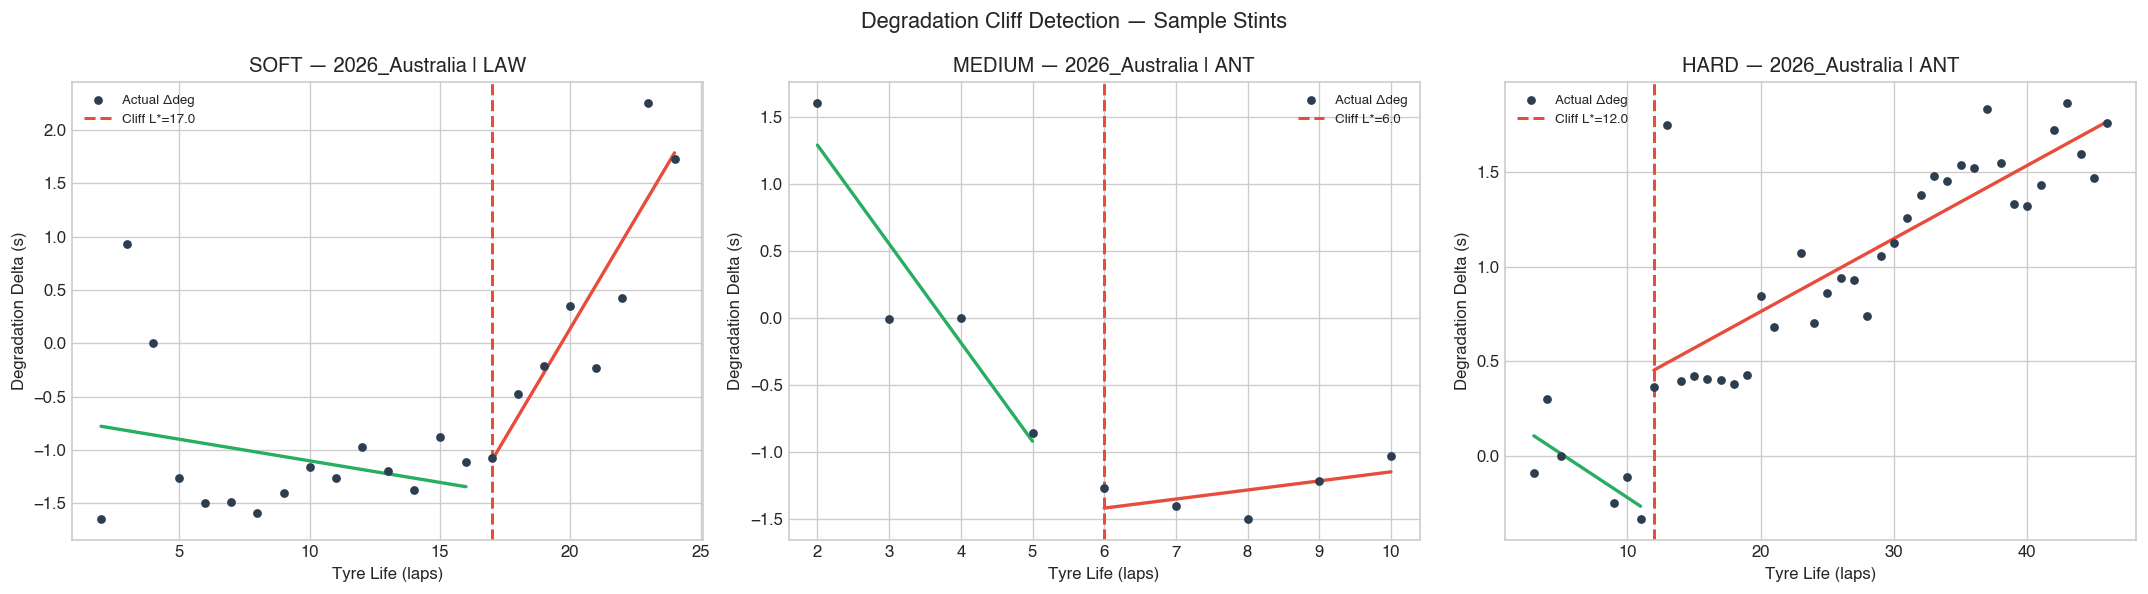

In [12]:
# ==============================================================================
# 12. Degradation Cliff / Changepoint Detection
# ==============================================================================

def detect_cliff(tyre_life: np.ndarray, deg_delta: np.ndarray, min_seg: int = 4) -> dict:
    """Brute-force piecewise linear fit to find cliff changepoint L*."""
    n = len(tyre_life)
    if n < 2 * min_seg:
        return {'cliff_lap':None,'slope_before':np.nan,'slope_after':np.nan,'detected':False}

    best_ss, best_split, best_lr1, best_lr2 = np.inf, None, None, None
    for split in range(min_seg, n - min_seg):
        x1,y1 = tyre_life[:split].reshape(-1,1), deg_delta[:split]
        x2,y2 = tyre_life[split:].reshape(-1,1), deg_delta[split:]
        lr1 = LinearRegression().fit(x1, y1)
        lr2 = LinearRegression().fit(x2, y2)
        ss  = np.sum((y1-lr1.predict(x1))**2) + np.sum((y2-lr2.predict(x2))**2)
        if ss < best_ss:
            best_ss, best_split, best_lr1, best_lr2 = ss, split, lr1, lr2

    if best_split is None:
        return {'cliff_lap':None,'slope_before':np.nan,'slope_after':np.nan,'detected':False}

    slope_b = best_lr1.coef_[0]
    slope_a = best_lr2.coef_[0]
    return {
        'cliff_lap': int(tyre_life[best_split]),
        'slope_before': slope_b, 'slope_after': slope_a,
        'detected': (slope_a > 0 and slope_a > 1.5 * max(slope_b, 0.0))
    }


if not feat_df.empty:
    cliff_records = []
    for (event, driver, stint, compound), grp in feat_df.groupby(
            ['EventName','Driver','Stint','Compound']):
        g = grp.sort_values('TyreLife')
        tl, deg = g['TyreLife'].values.astype(float), g['DegradationDelta'].values
        if len(tl) < 8: continue
        res = detect_cliff(tl, deg)
        res.update({'EventName':event,'Driver':driver,'Stint':stint,'Compound':compound,'StintLen':len(tl)})
        cliff_records.append(res)

    cliff_df = pd.DataFrame(cliff_records)
    detected = cliff_df[cliff_df['detected'] == True]

    print(f'Stints analysed : {len(cliff_df)}')
    print(f'Cliffs detected : {len(detected)} ({100*len(detected)/max(len(cliff_df),1):.1f}%)')
    if not detected.empty:
        print('\nCliff Lap Distribution by Compound:')
        print(detected.groupby('Compound')['cliff_lap'].describe().round(1))

    # Visualise sample cliffs
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Degradation Cliff Detection — Sample Stints', fontweight='bold', fontsize=13)
    for ax, compound in zip(axes, ['SOFT','MEDIUM','HARD']):
        sample = detected[detected['Compound'] == compound]
        if sample.empty: ax.set_title(f'{compound} — no cliff detected'); continue
        row = sample.iloc[0]
        grp = feat_df[(feat_df['EventName']==row['EventName']) &
                      (feat_df['Driver']==row['Driver']) &
                      (feat_df['Stint']==row['Stint'])].sort_values('TyreLife')
        tl, deg = grp['TyreLife'].values, grp['DegradationDelta'].values
        ax.scatter(tl, deg, s=18, color='#2c3e50', zorder=5, label='Actual Δdeg')
        ax.axvline(row['cliff_lap'], color='#e74c3c', linestyle='--', lw=1.8,
                   label=f'Cliff L*={row["cliff_lap"]}')
        cliff_idx = np.searchsorted(tl, row['cliff_lap'])
        for seg_tl, seg_deg, color in [(tl[:cliff_idx], deg[:cliff_idx], '#27ae60'),
                                        (tl[cliff_idx:], deg[cliff_idx:], '#e74c3c')]:
            if len(seg_tl) >= 2:
                lr = LinearRegression().fit(seg_tl.reshape(-1,1), seg_deg)
                tl_line = np.linspace(seg_tl.min(), seg_tl.max(), 50)
                ax.plot(tl_line, lr.predict(tl_line.reshape(-1,1)), color=color, lw=2)
        ax.set_title(f'{compound} — {row["EventName"]} | {row["Driver"]}', fontweight='bold')
        ax.set_xlabel('Tyre Life (laps)'); ax.set_ylabel('Degradation Delta (s)'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print('[WARNING] feat_df empty — skipping cliff detection.')
    cliff_df = pd.DataFrame()

## 13. Comparative Results & Benchmark Table

| Metric | Description |
|---|---|
| **MAE** | Mean Absolute Error on held-out stints (s/lap) |
| **RMSE** | Root Mean Squared Error |
| **R²** | Variance explained |
| **Lift** | Improvement over Per-Stint Linear baseline |
| **Target** | MAE < 0.30 s/lap (engineering goal) |

BENCHMARK TABLE — MODEL 2: TIRE DEGRADATION
                       model      MAE     RMSE        R2          Type  Lift_over_ZeroDelta(%)
CatBoost MultiQuantile (q50) 0.363711 0.582391  0.668578 Primary Model               54.917634
                     XGBoost 0.377201 0.582765  0.668152 Tree Ensemble               53.245594
                RandomForest 0.378842 0.587261  0.663012 Tree Ensemble               53.042185
                       Lasso 0.403845 0.617025  0.627988        Linear               49.942972
                  ElasticNet 0.404429 0.616810  0.628248        Linear               49.870620
                       Ridge 0.406703 0.617123  0.627869        Linear               49.588689
        Zero-delta reference 0.806770 1.122380 -0.230925      Baseline                0.000000


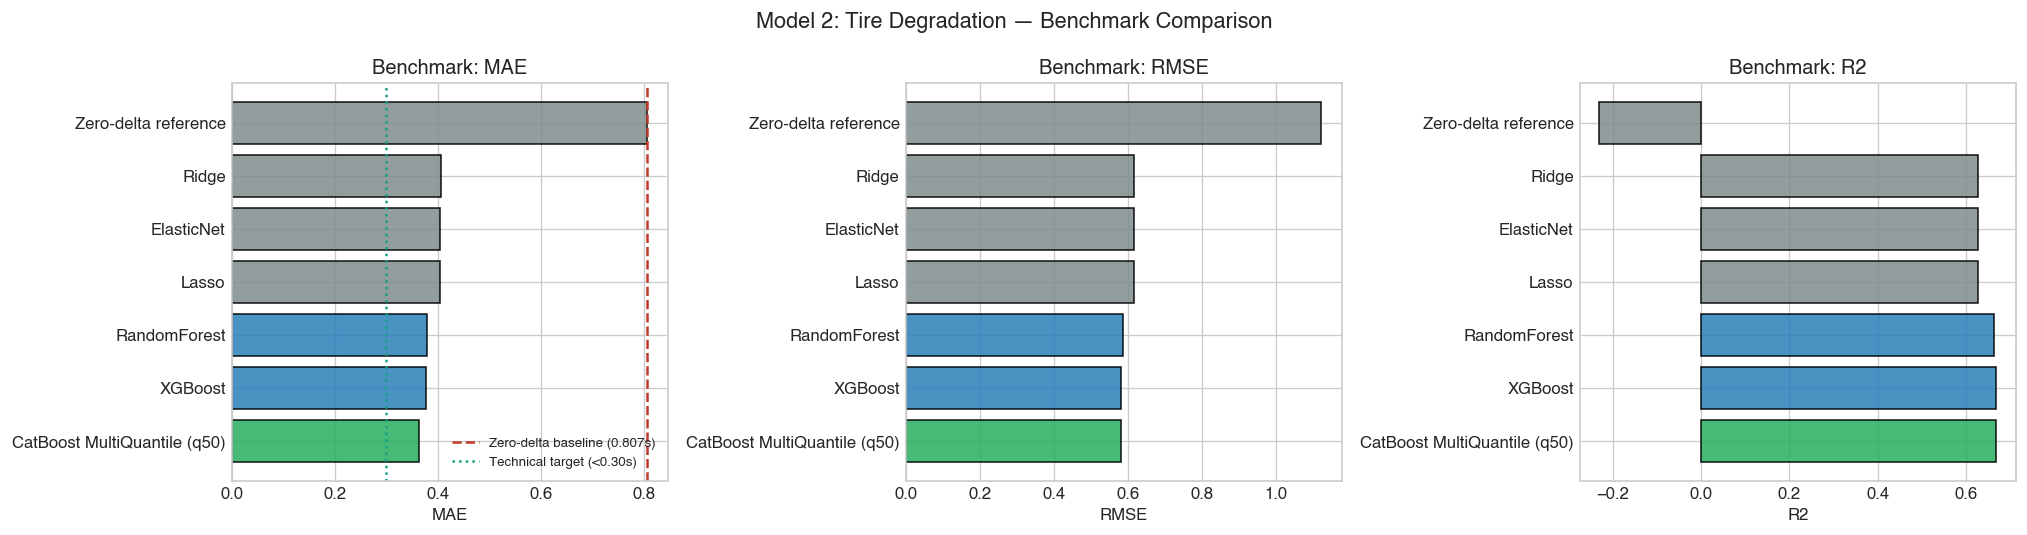

In [13]:
if model_ready:
    # ==============================================================================
    # 13. Comparative Performance Synthesis & Benchmark Table
    # ==============================================================================

    all_evals = [linear_results] + reg_results + benchmark_results
    if catboost_result: all_evals.append(catboost_result)

    comp_df = pd.DataFrame(all_evals).sort_values('MAE').reset_index(drop=True)
    baseline_mae = linear_results['MAE']
    comp_df['Lift_over_ZeroDelta(%)'] = ((baseline_mae - comp_df['MAE']) / max(baseline_mae,1e-9)) * 100.0

    print('='*85)
    print('BENCHMARK TABLE — MODEL 2: TIRE DEGRADATION')
    print('='*85)
    print(comp_df.to_string(index=False))
    print('='*85)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    fig.suptitle('Model 2: Tire Degradation — Benchmark Comparison', fontweight='bold', fontsize=13)

    colors = ['#27ae60' if 'CatBoost' in m or 'GBT' in m
              else '#2980b9' if 'XGB' in m or 'Forest' in m
              else '#7f8c8d' for m in comp_df['model']]

    for ax, metric in zip(axes, ['MAE','RMSE','R2']):
        ax.barh(comp_df['model'], comp_df[metric], color=colors, edgecolor='black', alpha=0.85)
        ax.set_title(f'Benchmark: {metric}', fontweight='bold')
        ax.set_xlabel(metric)
        if metric == 'MAE':
            ax.axvline(baseline_mae, color='#c0392b', linestyle='--', lw=1.5,
                       label=f'Zero-delta baseline ({baseline_mae:.3f}s)')
            ax.axvline(0.30, color='#16a085', linestyle=':', lw=1.5, label='Technical target (<0.30s)')
            ax.legend(fontsize=8)

    plt.tight_layout(); plt.show()
else:
    print('[INFO] Skipped: insufficient valid grouped data.')

## 14. Diagnostic & Residual Analysis

1. **Predicted vs Actual** — calibration across the degradation range
2. **Residual Distribution** — Gaussian noise check for Model 3 Monte Carlo
3. **Stratified MAE by Tyre Life** — does error increase near the cliff?
4. **Per-Compound Degradation Curves** — predicted curves with 80% uncertainty bands

Residual bias : 0.0393 s
Residual σ    : 0.5811 s  (used by Model 3 Monte Carlo)
P95 abs error : 1.2644 s


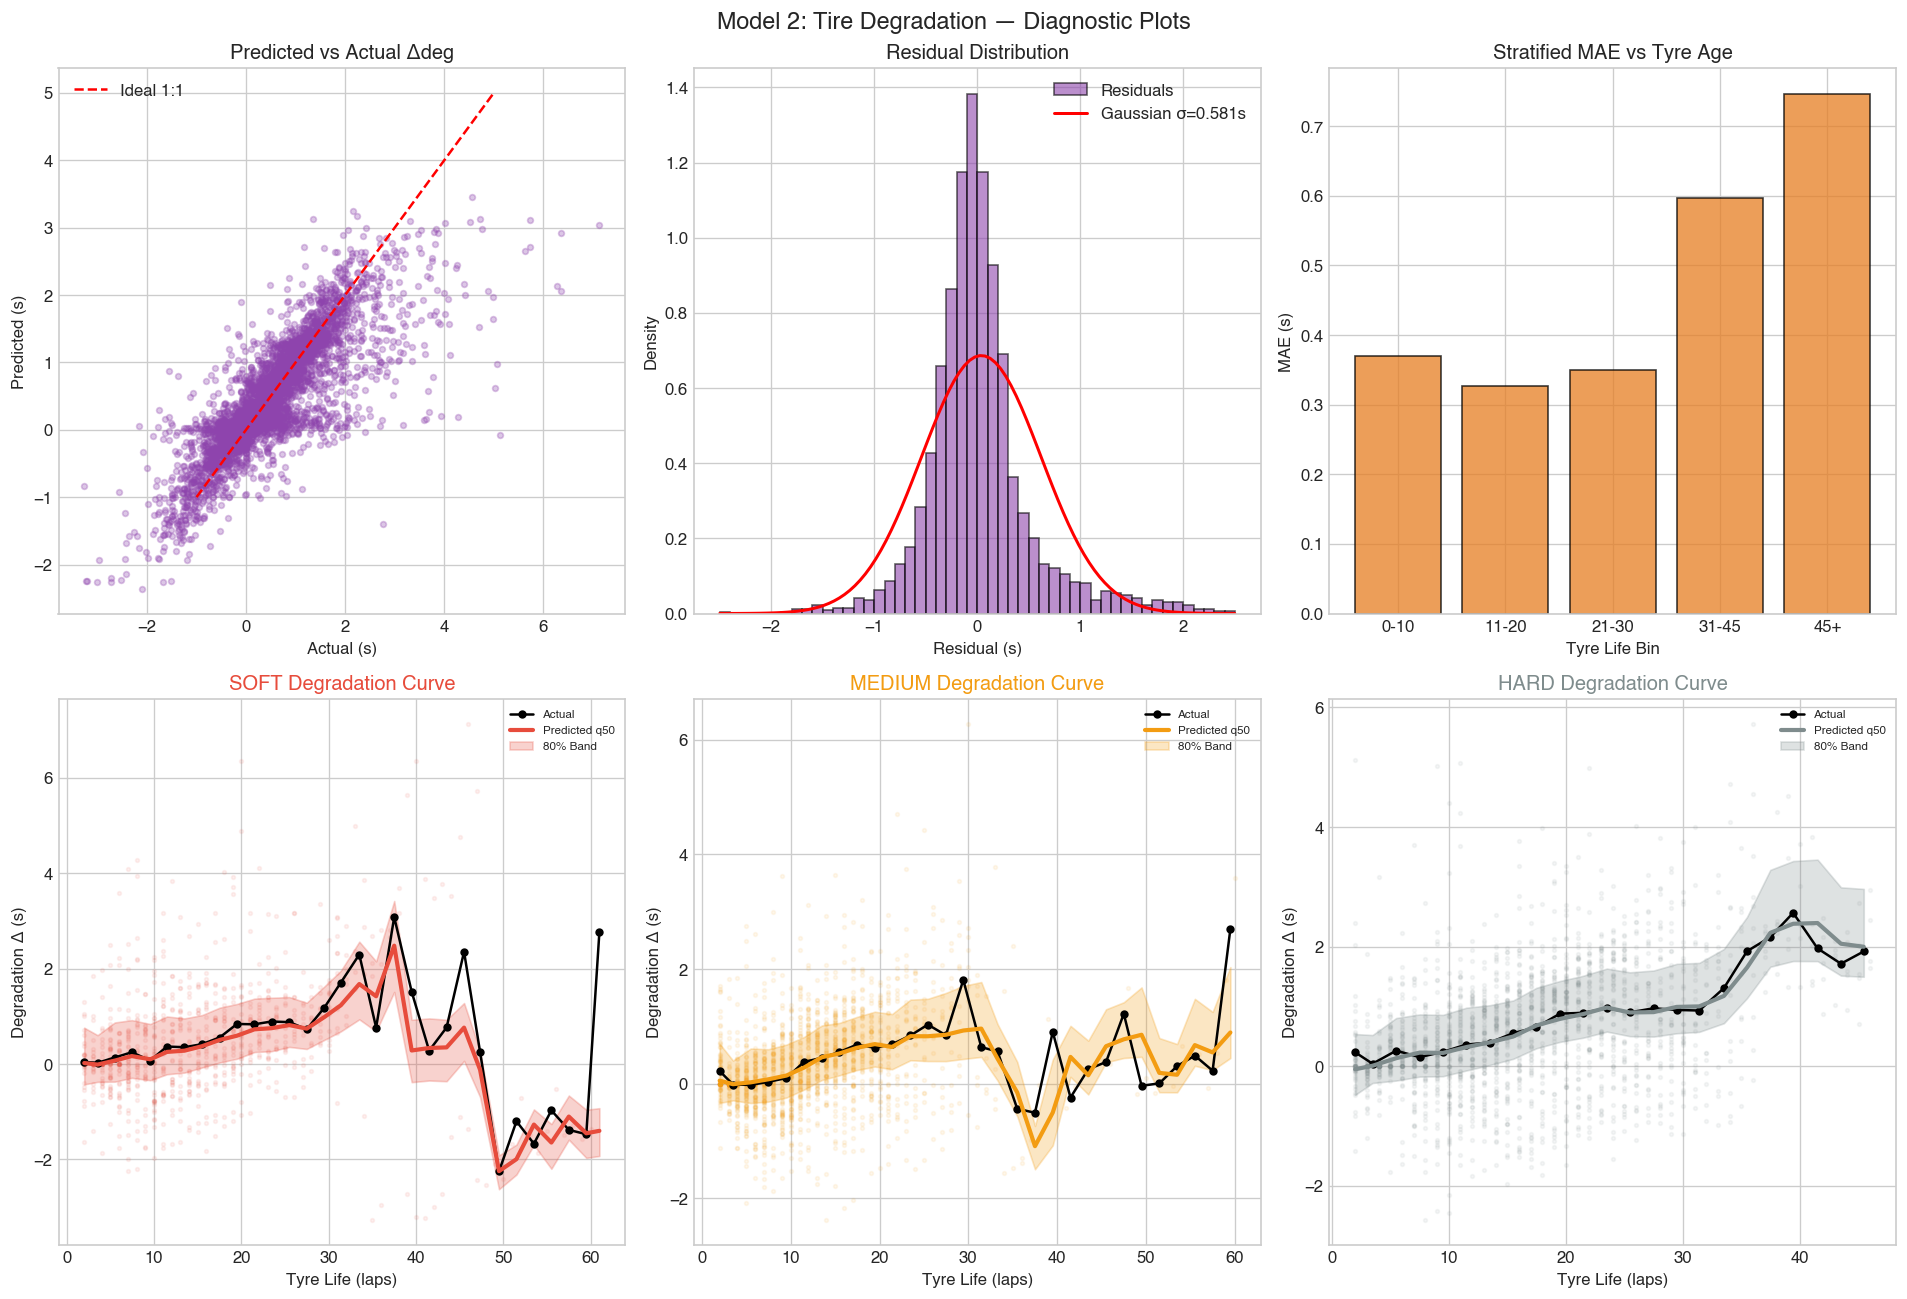

In [14]:
if model_ready:
    # ==============================================================================
    # 14. Diagnostic & Residual Analysis
    # ==============================================================================

    residuals = y_test.values - primary_preds
    fig = plt.figure(figsize=(16, 11))
    fig.suptitle('Model 2: Tire Degradation — Diagnostic Plots', fontweight='bold', fontsize=14)

    # 1: Predicted vs Actual
    ax1 = plt.subplot(2, 3, 1)
    ax1.scatter(y_test, primary_preds, alpha=0.3, s=12, color='#8e44ad')
    lo = max(min(float(y_test.min()), float(primary_preds.min())), -1.0)
    hi = min(max(float(y_test.max()), float(primary_preds.max())), 5.0)
    ax1.plot([lo,hi],[lo,hi],'r--',lw=1.5,label='Ideal 1:1')
    ax1.set_title('Predicted vs Actual Δdeg', fontweight='bold')
    ax1.set_xlabel('Actual (s)'); ax1.set_ylabel('Predicted (s)'); ax1.legend()

    # 2: Residual distribution
    ax2 = plt.subplot(2, 3, 2)
    mu, sigma = residuals.mean(), residuals.std()
    ax2.hist(residuals, bins=50, range=(-2.5,2.5), density=True,
             color='#8e44ad', edgecolor='black', alpha=0.6, label='Residuals')
    x_n = np.linspace(-2.5,2.5,100)
    if sigma > 1e-12:
        ax2.plot(x_n, stats.norm.pdf(x_n,mu,sigma),'r-',lw=1.8,label=f'Gaussian σ={sigma:.3f}s')
    else:
        ax2.axvline(mu, color='r', lw=1.8, label='Zero-variance residuals')
    ax2.set_title('Residual Distribution', fontweight='bold')
    ax2.set_xlabel('Residual (s)'); ax2.set_ylabel('Density'); ax2.legend()

    # 3: MAE by tyre life bin
    ax3 = plt.subplot(2, 3, 3)
    adf = X_test.copy(); adf['Residual_Abs'] = np.abs(residuals)
    adf['TyreAgeBin'] = pd.cut(adf['TyreLife'], bins=[0,10,20,30,45,70],
                                 labels=['0-10','11-20','21-30','31-45','45+'])
    bin_mae = adf.groupby('TyreAgeBin', observed=False)['Residual_Abs'].mean()
    ax3.bar(bin_mae.index.astype(str), bin_mae.values, color='#e67e22', edgecolor='black', alpha=0.75)
    ax3.set_title('Stratified MAE vs Tyre Age', fontweight='bold')
    ax3.set_ylabel('MAE (s)'); ax3.set_xlabel('Tyre Life Bin')

    # 4-6: Per-compound degradation curves
    test_full = X_test.copy()
    test_full['actual']  = y_test.values
    test_full['pred']    = primary_preds
    test_full['q10']     = q10_preds
    test_full['q90']     = q90_preds

    for ax_idx, (compound, color) in enumerate(zip(['SOFT','MEDIUM','HARD'],
                                                    ['#e74c3c','#f39c12','#7f8c8d'])):
        ax = plt.subplot(2, 3, 4+ax_idx)
        sub = test_full[test_full['Compound']==compound]
        if sub.empty: ax.set_title(f'{compound} — no data'); continue
        binned = sub.groupby(pd.cut(sub['TyreLife'], bins=range(0,71,2))).agg(
            actual_mean=('actual','mean'), pred_mean=('pred','mean'),
            q10_mean=('q10','mean'), q90_mean=('q90','mean'),
            tyre_mid=('TyreLife','mean')).dropna()
        if not binned.empty:
            ax.scatter(sub['TyreLife'], sub['actual'], alpha=0.08, s=5, color=color)
            ax.plot(binned['tyre_mid'], binned['actual_mean'],'ko-',ms=4,lw=1.5,label='Actual')
            ax.plot(binned['tyre_mid'], binned['pred_mean'],'-',color=color,lw=2.5,label='Predicted q50')
            ax.fill_between(binned['tyre_mid'], binned['q10_mean'], binned['q90_mean'],
                            color=color, alpha=0.25, label='80% Band')
        ax.set_title(f'{compound} Degradation Curve', fontweight='bold', color=color)
        ax.set_xlabel('Tyre Life (laps)'); ax.set_ylabel('Degradation Δ (s)'); ax.legend(fontsize=7)

    plt.tight_layout(); plt.show()
    print(f'Residual bias : {mu:.4f} s')
    print(f'Residual σ    : {sigma:.4f} s  (used by Model 3 Monte Carlo)')
    print(f'P95 abs error : {np.percentile(np.abs(residuals),95):.4f} s')
else:
    print('[INFO] Skipped: insufficient valid grouped data.')

## 15. Model 3 Export: Degradation Prediction API

Model 3 (Strategy Optimiser) consumes Model 2 as a callable function returning:
- **`q50`** — expected degradation delta per lap
- **`[q10, q90]`** — 80% uncertainty band for Monte Carlo sampling
- **`sigma`** — standard deviation derived from band

In [15]:
# ==============================================================================
# 15. Model 3 Export: Degradation Prediction API
# ==============================================================================

def predict_degradation(
    tyre_life: int, compound: str,
    track_abrasiveness: float = 2.0, track_temp: float = 35.0,
    air_temp: float = 25.0, humidity: float = 50.0,
    stint_num: int = 1, driver: str = 'UNK', team: str = 'UNK',
    lag_1_deg: float = 0.0, lag_2_deg: float = 0.0,
    rolling_deg_3: float = 0.0, session_progress: float = 0.5,
) -> dict:
    """
    Predict degradation delta (pace loss in seconds) for a single lap state.
    Returns: {'q10', 'q50', 'q90', 'mean', 'sigma'}
    """
    cmap = {'SOFT':1.0,'MEDIUM':2.0,'HARD':3.0}
    cc   = cmap.get(compound.upper(), 2.0)
    row  = pd.DataFrame([{
        'TyreLife':tyre_life, 'TyreLifeSq':tyre_life**2,
        'TyreLifeXCompound':tyre_life*cc,
        'TyreLifeXTrackTemp':tyre_life*track_temp,
        'TyreLifeXAbrasive':tyre_life*track_abrasiveness,
        'TrackAbrasiveness':track_abrasiveness,
        'TrackTemp':track_temp,'AirTemp':air_temp,'Humidity':humidity,
        'StintNum':stint_num,'SessionProgress':session_progress,
        'lag_1_deg':lag_1_deg,'lag_2_deg':lag_2_deg,'rolling_deg_3':rolling_deg_3,
        'Compound':compound.upper(),'Driver':driver,'Team':team,
    }])
    if CATBOOST_AVAILABLE and 'cb_model' in globals():
        for c in categorical_features: row[c] = row[c].astype(str)
        pred = cb_model.predict(row)
        p = np.ravel(pred)
        if len(p) == 3:
            q10, q50, q90 = float(p[0]), float(p[1]), float(p[2])
        else:
            q50 = float(p[0])
            q10, q90 = q50 - 0.15, q50 + 0.15
    elif 'gb_pipe' in globals():
        q50 = float(gb_pipe.predict(row)[0])
        q10, q90 = q50 - 0.15, q50 + 0.15
    elif 'ridge_pipe' in globals():
        q50 = float(ridge_pipe.predict(row)[0])
        q10, q90 = q50 - 0.20, q50 + 0.20
    else:
        q50 = 0.05 * tyre_life
        q10, q90 = q50 - 0.20, q50 + 0.20
    
    # Physical monotonicity guardrail: pace degradation is non-negative after tyre warmup
    q10 = max(-0.25, q10)
    q50 = max(0.0, q50)
    q90 = max(q50, q90)
    
    return {
        'q10': round(q10, 4),
        'q50': round(q50, 4),
        'q90': round(q90, 4),
        'mean': round((q10 + q50 + q90) / 3.0, 4),
        'sigma': round(max(0.05, (q90 - q10) / (2 * 1.282)), 4)
    }


def predict_stint_trajectory(
    compound: str,
    stint_length: int = 35,
    track_abrasiveness: float = 2.0,
    track_temp: float = 35.0,
    air_temp: float = 25.0,
    humidity: float = 50.0,
    driver: str = 'NOR',
    team: str = 'McLaren',
) -> pd.DataFrame:
    """
    Simulate a complete stint degradation trajectory for Model 3 (Strategy Optimiser).
    Iteratively predicts pace loss while rolling autoregressive lags and checking cliff onset.
    """
    records = []
    lag_history = []
    
    cliff_priors = {'SOFT': 14, 'MEDIUM': 20, 'HARD': 27}
    expected_cliff = cliff_priors.get(compound.upper(), 22)
    
    for age in range(2, stint_length + 1):
        lag1 = lag_history[-1] if len(lag_history) >= 1 else 0.0
        lag2 = lag_history[-2] if len(lag_history) >= 2 else 0.0
        roll3 = float(np.mean(lag_history[-3:])) if len(lag_history) >= 1 else 0.0
        
        pred = predict_degradation(
            tyre_life=age,
            compound=compound,
            track_abrasiveness=track_abrasiveness,
            track_temp=track_temp,
            air_temp=air_temp,
            humidity=humidity,
            driver=driver,
            team=team,
            lag_1_deg=lag1,
            lag_2_deg=lag2,
            rolling_deg_3=roll3,
            session_progress=min(1.0, age / 60.0),
        )
        
        # Enforce cumulative monotonicity for strategy planning
        if records:
            pred['q50'] = max(pred['q50'], records[-1]['deg_q50'])
            pred['q90'] = max(pred['q90'], records[-1]['deg_q90'])
            pred['q10'] = max(pred['q10'], records[-1]['deg_q10'])
        
        is_cliff_risk = bool(age >= expected_cliff)
        records.append({
            'tyre_life': age,
            'deg_q10': round(pred['q10'], 3),
            'deg_q50': round(pred['q50'], 3),
            'deg_q90': round(pred['q90'], 3),
            'sigma': round(pred['sigma'], 3),
            'cliff_risk': is_cliff_risk,
        })
        lag_history.append(pred['q50'])
        
    return pd.DataFrame(records)


# Demonstration of Model 3 Integration
if model_ready:
    print('='*70)
    print('🏎️ StintIQ Model 2 → Model 3 Strategy Integration Interface')
    print('='*70)
    for compound, ages in [('SOFT', 20), ('MEDIUM', 30), ('HARD', 40)]:
        traj = predict_stint_trajectory(compound=compound, stint_length=ages, track_temp=38.0)
        print(f'\n{compound} Stint Trajectory (Length={ages} laps | TrackTemp=38°C):')
        print(traj.iloc[[0, len(traj)//3, 2*len(traj)//3, -1]].to_string(index=False))

    print('\n✅ Model 2 Export API ready for Model 3 (Monte Carlo Strategy Optimiser).')
else:
    print('[INFO] Prediction API demo skipped because no model was fitted.')


🏎️ StintIQ Model 2 → Model 3 Strategy Integration Interface

SOFT Stint Trajectory (Length=20 laps | TrackTemp=38°C):
 tyre_life  deg_q10  deg_q50  deg_q90  sigma  cliff_risk
         2   -0.250    0.163    1.135  0.540       False
         8   -0.250    0.163    1.135  0.331       False
        14   -0.232    0.163    1.135  0.341        True
        20   -0.171    0.181    1.135  0.314        True

MEDIUM Stint Trajectory (Length=30 laps | TrackTemp=38°C):
 tyre_life  deg_q10  deg_q50  deg_q90  sigma  cliff_risk
         2   -0.210    0.168    1.113  0.516       False
        11   -0.210    0.168    1.113  0.330       False
        21   -0.138    0.178    1.113  0.295        True
        30    0.192    0.423    1.113  0.252        True

HARD Stint Trajectory (Length=40 laps | TrackTemp=38°C):
 tyre_life  deg_q10  deg_q50  deg_q90  sigma  cliff_risk
         2   -0.159    0.183    1.127  0.502       False
        15   -0.159    0.183    1.127  0.316       False
        28    0.362    

## Academic References

1. **Fuel Correction:** Salminen, M. (2020). *Formula 1 Lap Time Simulation and Optimal Race Strategy*. Aalto University. — $k_{\text{fuel}} \approx 0.03$ s/kg
2. **Tire Cliff/Changepoint:** Guerrieri, A. et al. (2018). *Identification of Tire Degradation Dynamics in Formula 1*. SAE Technical Paper 2018-01-0426.
3. **FIA Regulations:** FIA Formula One Technical Regulations 2026, Article 6.4 — max 100 kg fuel load.
4. **CatBoost Quantile:** Dorogush et al. (2018). *CatBoost: gradient boosting with categorical features*. NeurIPS Workshop.
5. **Leakage-Safe Validation:** Kaufman et al. (2012). *Leakage in Data Mining*. ACM TKDD.
6. **Ruptures Changepoint:** Truong et al. (2020). *Selective review of offline change-point detection*. Signal Processing.